In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

In [ ]:

df = pd.read_csv("car_price.csv")
numeric_features = ["symboling", "wheelbase", "carlength", "carwidth", "carheight",
"curbweight", "enginesize", "boreratio", "stroke",
"compressionratio", "horsepower", "peakrpm", "citympg", "highwaympg"]
target = "price"
X = df[numeric_features]
y = df[target]

In [ ]:

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:

linear_model = LinearRegression()
ridge_model = Ridge(alpha=1.0)
lasso_model = Lasso(alpha=0.1, max_iter=10000)

In [ ]:

linear_model.fit(X_train_scaled, y_train)
ridge_model.fit(X_train_scaled, y_train)
lasso_model.fit(X_train_scaled, y_train)

Lasso(alpha=0.1, max_iter=10000)

In [ ]:

linear_pred = linear_model.predict(X_test_scaled)
ridge_pred = ridge_model.predict(X_test_scaled)
lasso_pred = lasso_model.predict(X_test_scaled)

In [ ]:

def evaluate_model(name, y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)

    return {
        "Model": name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2 Score": r2
    }

results = [
    evaluate_model("Linear Regression", y_test, linear_pred),
    evaluate_model("Ridge Regression", y_test, ridge_pred),
    evaluate_model("Lasso Regression", y_test, lasso_pred)
]

results_df = pd.DataFrame(results)

print(results_df)

               Model          MAE           MSE         RMSE  R2 Score
0  Linear Regression  2986.835065  1.658668e+07  4072.674304  0.779848
1   Ridge Regression  2963.769155  1.635154e+07  4043.704147  0.782969
2   Lasso Regression  2986.776306  1.658600e+07  4072.591844  0.779857


In [ ]:

coef_df = pd.DataFrame({
"Feature": numeric_features,
"Linear Regression": linear_model.coef_,
"Ridge Regression": ridge_model.coef_,
"Lasso Regression": lasso_model.coef_,
})
print(coef_df)

             Feature  Linear Regression  Ridge Regression  Lasso Regression
0          symboling         247.378595        254.762143        247.165114
1          wheelbase        1106.570332        990.281876       1105.409624
2          carlength       -1381.727586      -1211.846502      -1379.331463
3           carwidth        1216.593351       1193.069830       1216.485310
4          carheight         424.081437        405.089087        423.702519
5         curbweight         229.089420        355.257990        227.417846
6         enginesize        4896.310431       4647.295826       4895.763736
7          boreratio        -353.366688       -349.672617       -353.135814
8             stroke        -993.083531       -952.580430       -992.743778
9   compressionratio        1271.188815       1184.637274       1270.845427
10        horsepower         775.528364        957.455617        776.420466
11           peakrpm         931.211186        879.741028        930.903535
12          

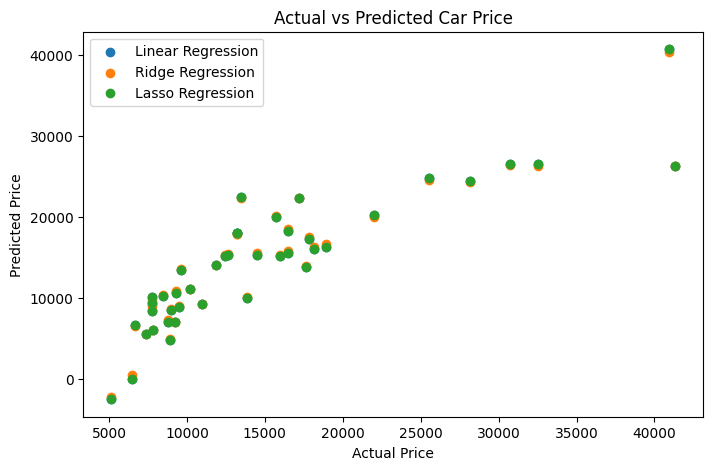

In [ ]:

plt.figure(figsize=(8, 5))
plt.scatter(y_test, linear_pred, label="Linear Regression")
plt.scatter(y_test, ridge_pred, label="Ridge Regression")
plt.scatter(y_test, lasso_pred, label="Lasso Regression")
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted Car Price")
plt.legend()
plt.show()

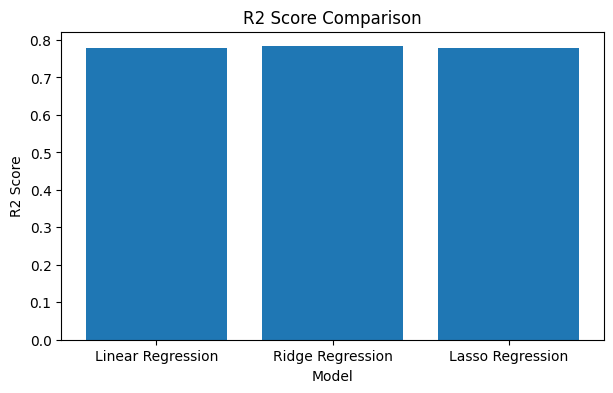

In [ ]:

plt.figure(figsize=(7, 4))
plt.bar(results_df["Model"], results_df["R2 Score"])
plt.xlabel("Model")
plt.ylabel("R2 Score")
plt.title("R2 Score Comparison")
plt.show()